# Figure 3A: epistatic coefficient heatmaps

First-order, pairwise and higher-order coefficients from the fitted censored regressions, one block per antibody. First-order and higher-order cells are split by antigen; pairwise coefficients fill the upper triangle for SF162 and the lower for CH505TF, with the diagonal masked. Color limits are global across all antibodies so blocks compare directly. Antibodies without a proper  fit for both antigens are skipped.

In [ ]:
import re
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd

%matplotlib inline

In [ ]:
import os

data_dir = "../data"
fig_dir = "../figures"
os.makedirs(fig_dir, exist_ok=True)
PNG_DPI = 300

plt.rcParams["svg.fonttype"] = "path"   # illustrator drops live text
plt.rcParams["pdf.fonttype"] = 42

def save_figure(fig, stem):
    """Write png, pdf and svg, then check the svg has no live text."""
    path = f"{fig_dir}/{stem}"
    fig.savefig(f"{path}.png", dpi=PNG_DPI, bbox_inches="tight")
    fig.savefig(f"{path}.pdf", bbox_inches="tight")
    fig.savefig(f"{path}.svg", bbox_inches="tight")
    assert open(f"{path}.svg").read().count("<text") == 0, "live text in svg, check svg.fonttype"


ANTIBODIES = [
    "1NC9", "CH235.12", "VRC01", "VRC13", "VRC16",
    "VRC07", "N49P7", "NIH45-46", "VRC-PG20",
]
ANTIGENS = ("CH505TF", "SF162")

FINAL_FILE_STEM = {
    "1NC9": "1NC9", "CH235.12": "CH235_12", "VRC01": "VRC01",
    "VRC13": "VRC13", "VRC16": "VRC16", "VRC07": "VRC07",
    "N49P7": "N49P7", "NIH45-46": "NIH4546", "VRC-PG20": "VRCPG20",
}

KABAT_REGIONS = {
    "FW1": (1, 30),
    "CDRH1": (31, 35),
    "FW2": (36, 49),
    "CDRH2": (50, 65),
    "FW3": (66, 94),
    "CDRH3": (95, 102),
    "FW4": (103, 130),
}

In [ ]:
def get_kabat_region(kabat_position, regions=KABAT_REGIONS):
    # Returns Kabat region (e.g., FW1) for a given position.
    if pd.isna(kabat_position):
        return "unknown"
    p = int(kabat_position)
    for region, (lo, hi) in regions.items():
        if lo <= p <= hi:
            return region
    return "unknown"


def find_metadata_file(antibody):
    # Path to one antibody's site metadata.
    return f"{data_dir}/{FINAL_FILE_STEM[str(antibody).strip()]}_meta.csv"


def get_site_annotation_table(antibody):
    # Loads and processes site annotation metadata for an antibody.
    # Load the metadata CSV file
    meta = pd.read_csv(find_metadata_file(antibody))
    # Strip whitespace from column names
    meta.columns = meta.columns.str.strip()

    # Ensure 'site_index' column exists
    if "site_index" not in meta.columns:
        meta["site_index"] = (
            meta["site"].astype(str).str.replace("site_", "", regex=False)
            .str.extract(r"(\d+)", expand=False).astype(int)
        )

    # Convert kabat_position to string and extract numerical part
    meta["kabat_position"] = meta["kabat_position"].astype(str)
    meta["kabat_position_num"] = meta["kabat_position"].str.extract(r"(\d+)", expand=False).astype(float)
    # Create 'kabat_mutation' string
    meta["kabat_mutation"] = (
        meta["germline_aa"].astype(str) + meta["kabat_position"].astype(str) + meta["mature_aa"].astype(str)
    )

    # Assign 'region' based on kabat_position_num if not present/blank
    if "region" not in meta.columns:
        meta["region"] = meta["kabat_position_num"].apply(get_kabat_region)
    else:
        # Fill any NaN regions and convert to string
        meta["region"] = meta["region"].fillna("").astype(str)
        # Identify blank regions and apply get_kabat_region
        blank = meta["region"].str.len() == 0
        meta.loc[blank, "region"] = meta.loc[blank, "kabat_position_num"].apply(get_kabat_region)

    # Return processed DataFrame
    return meta[[
        "site_index", "kabat_position", "kabat_position_num",
        "kabat_mutation", "region", "germline_aa", "mature_aa",
    ]].sort_values("site_index").reset_index(drop=True)

In [ ]:
def find_final_params_file(antibody, antigen):
    # Best-fit coefficients for one complex, or None if it was not fitted.
    fp = f"{data_dir}/{FINAL_FILE_STEM[antibody]}_{antigen}_BEST_df_params.csv"
    return fp if os.path.exists(fp) else None

In [ ]:
import numpy as np
import pandas as pd
import re
import sys # Added this import for diagnostic prints

# Helper functions to wrap existing data loading for compatibility with the example code structure

def load_antibody_meta(antibody):
    return get_site_annotation_table(antibody)

def load_params(antibody, antigen):
    params_fp = find_final_params_file(antibody, antigen)
    if params_fp:
        params = pd.read_csv(params_fp)
        params.columns = params.columns.str.strip()
        # Explicitly convert 'coefficient' to numeric after loading
        params["coefficient"] = pd.to_numeric(params["coefficient"], errors="coerce")

        # Original term column content for debugging
        # if not params.empty:
        #     sys.stdout.write(f"DEBUG: Raw 'term' column for {antibody} {antigen} (first 5):\n")
        #     sys.stdout.write(params['term'].head().to_string() + "\n")
        #     sample_term_1 = params['term'].iloc[0]
        #     sys.stdout.write(f"DEBUG: Processing term '{sample_term_1}'\n")

        # The example code assumes 'site_list' and 'order' are present or derivable
        # Adapting from plot_order_heatmap logic to create these
        # CHANGED REGEX HERE: to extract any digits
        params["sites"] = params["term"].apply(
            lambda t: tuple(sorted(int(m) for m in re.findall(r"(\d+)", str(t))))) # Regex changed from "site_(\d+)" to "(\d+)"
        params["order"] = params["sites"].apply(len)
        # Rename 'sites' column to 'site_list' for compatibility with example code
        params = params.rename(columns={'sites': 'site_list'})

        # Diagnostic: Check the generated 'site_list' and 'order' columns
        # if not params.empty:
        #     sys.stdout.write(f"DEBUG IN load_params after processing for {antibody} {antigen}:\n")
        #     sys.stdout.write(f"  Processed 'term' (first 5):\n")
        #     sys.stdout.write(params[['term', 'site_list', 'order']].head().to_string() + "\n")
        #     sys.stdout.flush()

        return params
    else:
        return pd.DataFrame() # Return empty DataFrame if file not found

def signed_higher_order_site_load(params):
    # Higher-order coefficient per mutation: signed sum over all order >= 3 coefficients involving that site.

    high = params[params["order"].ge(3)].copy()

    all_sites = sorted(
        set(
            s
            for site_list in params["site_list"]
            for s in site_list
        )
    )

    rows = []

    for site in all_sites:
        touching = high[
            high["site_list"].apply(lambda x: int(site) in list(map(int, x))) # Ensure site_list elements are iterable
        ].copy()

        rows.append({
            "site_index": int(site),
            "higher_order_signed_sum": touching["coefficient"].sum() if len(touching) else 0.0,
            "higher_order_abs_sum": touching["coefficient"].abs().sum() if len(touching) else 0.0,
            "n_higher_order_terms": len(touching),
        })

    return pd.DataFrame(rows)

def build_pairwise_epistasis_tables(antibody, antigen):

    # Builds data for the heatmap: site_order, square pairwise matrix, same-width higher-order row, and labels.


    params = load_params(antibody, antigen).copy()

    # --- Diagnostic prints for params DataFrame ---
    # sys.stdout.write(f"--- build_pairwise_epistasis_tables for {antibody} {antigen} ---\n")
    # sys.stdout.write(f"Params loaded. Shape: {params.shape}\n")
    # if not params.empty:
    #     sys.stdout.write(f"Params head:\n{params.head().to_string()}\n")
    #     sys.stdout.write(f"Params 'coefficient' dtype: {params['coefficient'].dtype}\n")
    #     sys.stdout.write(f"Params 'coefficient' non-NaN sum: {params['coefficient'].sum()}\n")
    # else:
    #     sys.stdout.write("Params DataFrame is empty.\n")
    # sys.stdout.flush()

    meta = load_antibody_meta(antibody).copy()

    site_order = meta[
        ["site_index", "kabat_mutation", "kabat_position"]
    ].rename(columns={'kabat_mutation': 'kabat'}).copy()

    # Sort site_order by site_index to maintain consistent ordering for plotting
    site_order = site_order.sort_values("site_index").reset_index(drop=True)

    sites = site_order["site_index"].astype(int).tolist()
    labels = site_order["kabat"].astype(str).tolist()

    site_to_i = {s: i for i, s in enumerate(sites)}
    n = len(sites)

    # If no sites from metadata, return empty data to avoid plotting errors
    if n == 0:
        # sys.stdout.write(f"No sites from metadata for {antibody} {antigen}. Returning empty data.\n")
        # sys.stdout.flush()
        return {
            "site_order": site_order,
            "order1_row": np.array([]),
            "pair_matrix": np.array([]).reshape(0,0),
            "higher_row": np.array([]).reshape(0,0),
            "labels": [],
        }

    # order 1 terms
    order1_terms = params[params["order"].eq(1)].copy()
    # sys.stdout.write(f"Order 1 terms. Shape: {order1_terms.shape}\n")
    # if not order1_terms.empty:
    #     sys.stdout.write(f"Order 1 terms head:\n{order1_terms.head().to_string()}\n")
    #     sys.stdout.write(f"Order 1 terms 'coefficient' non-NaN sum: {order1_terms['coefficient'].sum()}\n")
    # else:
    #     sys.stdout.write("Order 1 terms DataFrame is empty.\n")
    # sys.stdout.flush()

    order1_row = np.full(n, np.nan)
    for _, r in order1_terms.iterrows():
        # Ensure site_list is not empty before accessing index 0
        if r["site_list"] and len(r["site_list"]) > 0:
            site_index = int(r["site_list"][0])
            if site_index in site_to_i:
                order1_row[site_to_i[site_index]] = r["coefficient"]

    # pairwise terms
    pair_terms = params[params["order"].eq(2)].copy()
    # sys.stdout.write(f"Pair terms. Shape: {pair_terms.shape}\n")
    # if not pair_terms.empty:
    #     sys.stdout.write(f"Pair terms head:\n{pair_terms.head().to_string()}\n")
    #     sys.stdout.write(f"Pair terms 'coefficient' non-NaN sum: {pair_terms['coefficient'].sum()}\n")
    # else:
    #     sys.stdout.write("Pair terms DataFrame is empty.\n")
    # sys.stdout.flush()

    pair_matrix = np.full((n, n), np.nan)

    for _, r in pair_terms.iterrows():
        site_list = list(map(int, r["site_list"])) # Ensure site_list elements are integers

        if len(site_list) != 2:
            continue

        s1, s2 = sorted(site_list)

        if s1 not in site_to_i or s2 not in site_to_i:
            continue

        i = site_to_i[s1]
        j = site_to_i[s2]
        coef = r["coefficient"]

        pair_matrix[i, j] = coef
        pair_matrix[j, i] = coef

    # higher order terms
    higher_site = signed_higher_order_site_load(params)

    # Handle case where higher_site is empty (no higher-order terms)
    if not higher_site.empty:
        site_order = site_order.merge(
            higher_site,
            on="site_index",
            how="left",
        )
    else:
        # Manually add expected columns with default 0.0 values
        site_order["higher_order_signed_sum"] = 0.0
        site_order["higher_order_abs_sum"] = 0.0
        site_order["n_higher_order_terms"] = 0 # Also add this one as it's generated by signed_higher_order_site_load

    # Fill any NaNs that might result from a left merge where some site_index values
    # in site_order were not present in higher_site
    site_order["higher_order_signed_sum"] = site_order["higher_order_signed_sum"].fillna(0)
    site_order["higher_order_abs_sum"] = site_order["higher_order_abs_sum"].fillna(0)
    site_order["n_higher_order_terms"] = site_order["n_higher_order_terms"].fillna(0)

    higher_row = site_order["higher_order_signed_sum"].values.reshape(1, -1)

    return {
        "site_order": site_order,
        "order1_row": order1_row,
        "pair_matrix": pair_matrix,
        "higher_row": higher_row,
        "labels": labels,
    }

In [ ]:
def _load_order_arrays(antibody, antigen, n):
    data = build_pairwise_epistasis_tables(antibody, antigen)
    # Ensure arrays are correctly shaped even if n changes or data is empty
    order1_row = data["order1_row"] if data["order1_row"].size > 0 else np.full(n, np.nan)
    pair_matrix = data["pair_matrix"] if data["pair_matrix"].size > 0 else np.full((n, n), np.nan)
    higher_row = data["higher_row"] if data["higher_row"].size > 0 else np.full(n, np.nan)

    # Ensure higher_row is 1D if it came back as (1, N) for consistency
    if higher_row.ndim == 2 and higher_row.shape[0] == 1:
        higher_row = higher_row[0]

    return order1_row, pair_matrix, higher_row

def _draw_antibody_heatmap_subpanels(
    ax1, ax2, ax3, n, labels,
    order1_a, pair_a, higher_a,
    order1_b, pair_b, higher_b,
    pair_cmap, pair_norm, higher_cmap, higher_norm,
    ag_a, ag_b,
    draw_ylabel=True, draw_xlabel=True,
    pair_zero_color=None # New argument for the specific zero color
):

    def finish_axes(ax, ncols, nrows):
        # No grid lines, no bold section outlines -- clean/subtle cell
        # blocks like the reference figure, not a boxed-in grid. Spines
        # are hidden entirely rather than styled.
        ax.set_xlim(-0.5, ncols - 0.5)
        ax.set_ylim(-0.5, nrows - 0.5)
        ax.invert_yaxis()  # row 0 at top, matching the single-antigen imshow version
        ax.set_aspect("equal")
        for spine in ax.spines.values():
            spine.set_visible(False)

    # Helper function to draw split cells for order-1 and higher-order rows
    def draw_split_cell(ax, row_idx, col_idx, val_a, val_b, cmap, norm, zero_color_override, use_zero_override_for_zero_values=True):
        # Define colors directly based on value for robust 0.0 handling
        color_a = None
        if np.isnan(val_a):
            color_a = "none" # Transparent for NaN
        elif use_zero_override_for_zero_values and np.isclose(val_a, 0.0):
            color_a = zero_color_override # Use the specific zero color
        else:
            color_a = cmap(norm(val_a))

        color_b = None
        if np.isnan(val_b):
            color_b = "none"
        elif use_zero_override_for_zero_values and np.isclose(val_b, 0.0):
            color_b = zero_color_override # Use the specific zero color
        else:
            color_b = cmap(norm(val_b))

        # Define corners of the cell
        TL = [col_idx - 0.5, row_idx - 0.5]
        TR = [col_idx + 0.5, row_idx - 0.5]
        BL = [col_idx - 0.5, row_idx + 0.5]
        BR = [col_idx + 0.5, row_idx + 0.5]

        # Top-left triangle (for antigen A)
        poly_tl = plt.Polygon(
            [TL, TR, BR],
            facecolor=color_a,
            edgecolor="none",
            transform=ax.transData
        )
        ax.add_patch(poly_tl)

        # Bottom-right triangle (for antigen B)
        poly_br = plt.Polygon(
            [TL, BL, BR],
            facecolor=color_b,
            edgecolor="none",
            transform=ax.transData
        )
        ax.add_patch(poly_br)

    def draw_cell_diagonals(ax, ncols, nrows):
        for i in range(nrows):
            for j in range(ncols):
                # Changed color to 'lightgray'
                ax.plot([j - 0.5, j + 0.5], [i - 0.5, i + 0.5], color='lightgray', linewidth=0.5, zorder=2) # Diagonal line from top-left to bottom-right


    # order-1 strip -- each cell split upper-right=ag_a, lower-left=ag_b
    for j in range(n):
        draw_split_cell(ax1, 0, j, order1_a[j], order1_b[j], pair_cmap, pair_norm, pair_zero_color, use_zero_override_for_zero_values=True)
    draw_cell_diagonals(ax1, n, 1)
    ax1.set_yticks([])
    ax1.set_xticks(range(n))
    ax1.tick_params(left=False, labelbottom=False, bottom=True, length=4)  # short bottom ticks, no labels -- bridges the gap to ax2
    finish_axes(ax1, n, 1)
    # order-2 grid -- split by the WHOLE matrix's main diagonal (one value
    # per cell, not each cell split into triangles): upper triangle (j>i)
    # = ag_a, lower triangle (j<i) = ag_b, diagonal (n/a) greyed out.
    upper_mask = np.triu(np.ones((n, n), dtype=bool), k=1)
    lower_mask = np.tril(np.ones((n, n), dtype=bool), k=-1)
    pair_combined = np.full((n, n), np.nan)
    pair_combined[upper_mask] = pair_a[upper_mask]
    pair_combined[lower_mask] = pair_b[lower_mask]

    pair_rgba = pair_cmap(pair_norm(pair_combined))
    pair_rgba[np.eye(n, dtype=bool)] = mcolors.to_rgba("0.45") # Still use PAIR_BAD_COLOR for the diagonal (n/a)
    ax2.imshow(pair_rgba, aspect="equal")


    if draw_ylabel:
        ax2.set_yticks(range(n)); ax2.set_yticklabels(labels, fontsize=9)
    else:
        ax2.set_yticks([])
    ax2.set_xticks(range(n))
    # Short tick marks (no labels) on both the top and bottom of the grid --
    # top ticks meet ax1's bottom ticks across the gap, bottom ticks meet
    # ax3's top ticks, so the three sections still read as one connected
    # grid despite the added hspace. No cell grid lines, no bold outline --
    # clean/subtle like the reference figure.
    ax2.tick_params(labelbottom=False, bottom=True, top=True, length=4)
    for spine in ax2.spines.values():
            spine.set_visible(False)
    ax2.set_xlim(-0.5, n - 0.5)
    ax2.set_ylim(n - 0.5, -0.5)  # imshow already puts row 0 at top; match finish_axes' orientation

    # order>2 strip
    for j in range(n):
        draw_split_cell(ax3, 0, j, higher_a[j], higher_b[j], higher_cmap, higher_norm, pair_zero_color, use_zero_override_for_zero_values=False)
    draw_cell_diagonals(ax3, n, 1)
    ax3.set_yticks([])
    if draw_xlabel:
        ax3.set_xticks(range(n)); ax3.set_xticklabels(labels, rotation=90, fontsize=7)
    else:
        ax3.set_xticks([])
    ax3.tick_params(left=False, bottom=True, top=True, length=4)  # top ticks bridge the gap to ax2
    finish_axes(ax3, n, 1)

def available_combos(antibodies=None, antigens=None):
    _antibodies = ANTIBODIES if antibodies is None else antibodies
    _antigens = ANTIGENS if antigens is None else antigens
    pairs = []
    for antibody in _antibodies:
        for antigen in _antigens:
            if find_final_params_file(antibody, antigen):
                pairs.append((antibody, antigen))
    return pairs

def plot_order_heatmap_split(
    antibody,
    figsize=(7, 7),
    out_name=None,
    show=False,
    manual_pair_absmax=None, # Renamed from pair_absmax
    higher_max=None,
    pair_cmap="RdBu_r",
    higher_cmap="PuRd",
    clip_absmax=None, # New parameter
):
    ag_a, ag_b = ANTIGENS

    meta = get_site_annotation_table(antibody)
    n = len(meta)
    labels = meta.sort_values("site_index")["kabat_mutation"].tolist()

    if n == 0:
        print(f"No sites found for {antibody}, skipping.")
        return

    order1_a, pair_a, higher_a = _load_order_arrays(antibody, ag_a, n)
    order1_b, pair_b, higher_b = _load_order_arrays(antibody, ag_b, n)

    _pair_absmax_for_norm = None
    _pair_absmax_for_ticks = None
    _pair_colorbar_extend = 'neither'

    if clip_absmax is not None:
        _pair_absmax_for_ticks = max(clip_absmax, 1e-6) # This is the value user specified for clipping and ticks
        # Use the exact clip_absmax for the norm range, as extending should handle the arrows
        _pair_absmax_for_norm = _pair_absmax_for_ticks
        _pair_colorbar_extend = 'both'
    elif manual_pair_absmax is not None:
        _pair_absmax_for_ticks = max(manual_pair_absmax, 1e-6)
        _pair_absmax_for_norm = _pair_absmax_for_ticks
        _pair_colorbar_extend = 'neither'
    else:
        # Auto-calculate if no explicit max is provided
        _calculated_pair_absmax = np.nanmax(
            np.concatenate([order1_a, order1_b, pair_a.ravel(), pair_b.ravel()])
        ) if (order1_a.size > 0 or order1_b.size > 0 or pair_a.size > 0 or pair_b.size > 0) else 1e-6
        _pair_absmax_for_ticks = max(_calculated_pair_absmax, 1e-6)
        _pair_absmax_for_norm = _pair_absmax_for_ticks
        _pair_colorbar_extend = 'neither'

    pair_norm = mcolors.TwoSlopeNorm(vmin=-_pair_absmax_for_norm, vcenter=0, vmax=_pair_absmax_for_norm)
    pair_cmap_obj = plt.get_cmap(pair_cmap).copy()
    pair_cmap_obj.set_bad(alpha=0) # Make NaNs transparent

    # Calculate the specific color for 0.0 for pairwise/order1,
    # as defined by the colormap and norm (with potential epsilon in norm limits, but vcenter=0 is precise)
    pair_zero_color = pair_cmap_obj(pair_norm(0.0))


    if higher_max is None:
        higher_max = np.nanmax(
            np.concatenate([higher_a.ravel(), higher_b.ravel()])
        ) if (higher_a.size > 0 or higher_b.size > 0) else 1e-6
    higher_max = max(higher_max, 1e-6)
    higher_norm = mcolors.Normalize(vmin=0, vmax=higher_max)
    higher_cmap_obj = plt.get_cmap(higher_cmap).copy()
    higher_cmap_obj.set_bad(alpha=0) # Make NaNs transparent

    fig = plt.figure(figsize=figsize, dpi=180)
    gs = fig.add_gridspec(3, 1, height_ratios=[1, n, 1], hspace=0.05, top=0.9, bottom=0.1, left=0.1, right=0.85)
    ax1 = fig.add_subplot(gs[0])
    ax2 = fig.add_subplot(gs[1])
    ax3 = fig.add_subplot(gs[2])

    _draw_antibody_heatmap_subpanels(
        ax1, ax2, ax3, n, labels,
        order1_a, pair_a, higher_a,
        order1_b, pair_b, higher_b,
        pair_cmap_obj, pair_norm, higher_cmap_obj, higher_norm,
        ag_a, ag_b,
        pair_zero_color=pair_zero_color
    )

    fig.suptitle(
        f"{antibody} order heatmap: first-order, pairwise, and higher-order mutational effects",
        fontsize=12,
        y=0.98,
    )
    fig.text(0.5, 0.94,
              f"pairwise grid: upper triangle = {ag_a}, lower triangle = {ag_b}   |   "
              f"order 1 / order>2 squares: upper-right = {ag_a}, lower-left = {ag_b}",
              transform=fig.transFigure, ha="center", va="center", fontsize=9, color="#333333")


    fig.canvas.draw()

    cax1 = fig.add_axes([0.88, 0.55, 0.015, 0.3]) # [left, bottom, width, height]
    cb1 = fig.colorbar(plt.cm.ScalarMappable(norm=pair_norm, cmap=pair_cmap_obj), cax=cax1, extend=_pair_colorbar_extend)
    if clip_absmax is not None:
        # Set custom ticks to include 0.25 and -0.25 if they are within the clip_absmax range
        ticks = sorted(list(set([-_pair_absmax_for_ticks, -0.25, 0, 0.25, _pair_absmax_for_ticks])))
        # Filter out ticks that are outside the range if _pair_absmax_for_ticks is smaller than 0.25
        ticks = [t for t in ticks if -_pair_absmax_for_ticks <= t <= _pair_absmax_for_ticks]
        cb1.set_ticks(ticks)

        # Create custom labels with <= and >= for the min/max ticks
        tick_labels = []
        for t in ticks:
            if np.isclose(t, -_pair_absmax_for_ticks):
                tick_labels.append(f"≤{t:g}")
            elif np.isclose(t, _pair_absmax_for_ticks):
                tick_labels.append(f"≥{t:g}")
            else:
                tick_labels.append(f"{t:g}")
        cb1.set_ticklabels(tick_labels)

    cb1.set_label("First-order &\npairwise coefficient", fontsize=8)

    cax2 = fig.add_axes([0.88, 0.15, 0.015, 0.2])
    cb2 = fig.colorbar(plt.cm.ScalarMappable(norm=higher_norm, cmap=higher_cmap_obj), cax=cax2)
    cb2.set_label("Higher-order\n(sum |coef|, order>2)", fontsize=8)

    out_name = out_name or f"{antibody}_split_by_antigen_order_heatmap.png"
    save_figure(plt.gcf(), Path(out_name).stem)
    if show:
        plt.show()
    else:
        plt.close(fig)
    return None

Saved: /root/Desktop/figures/final_fig/all_antibodies_global_split_order_heatmap.png


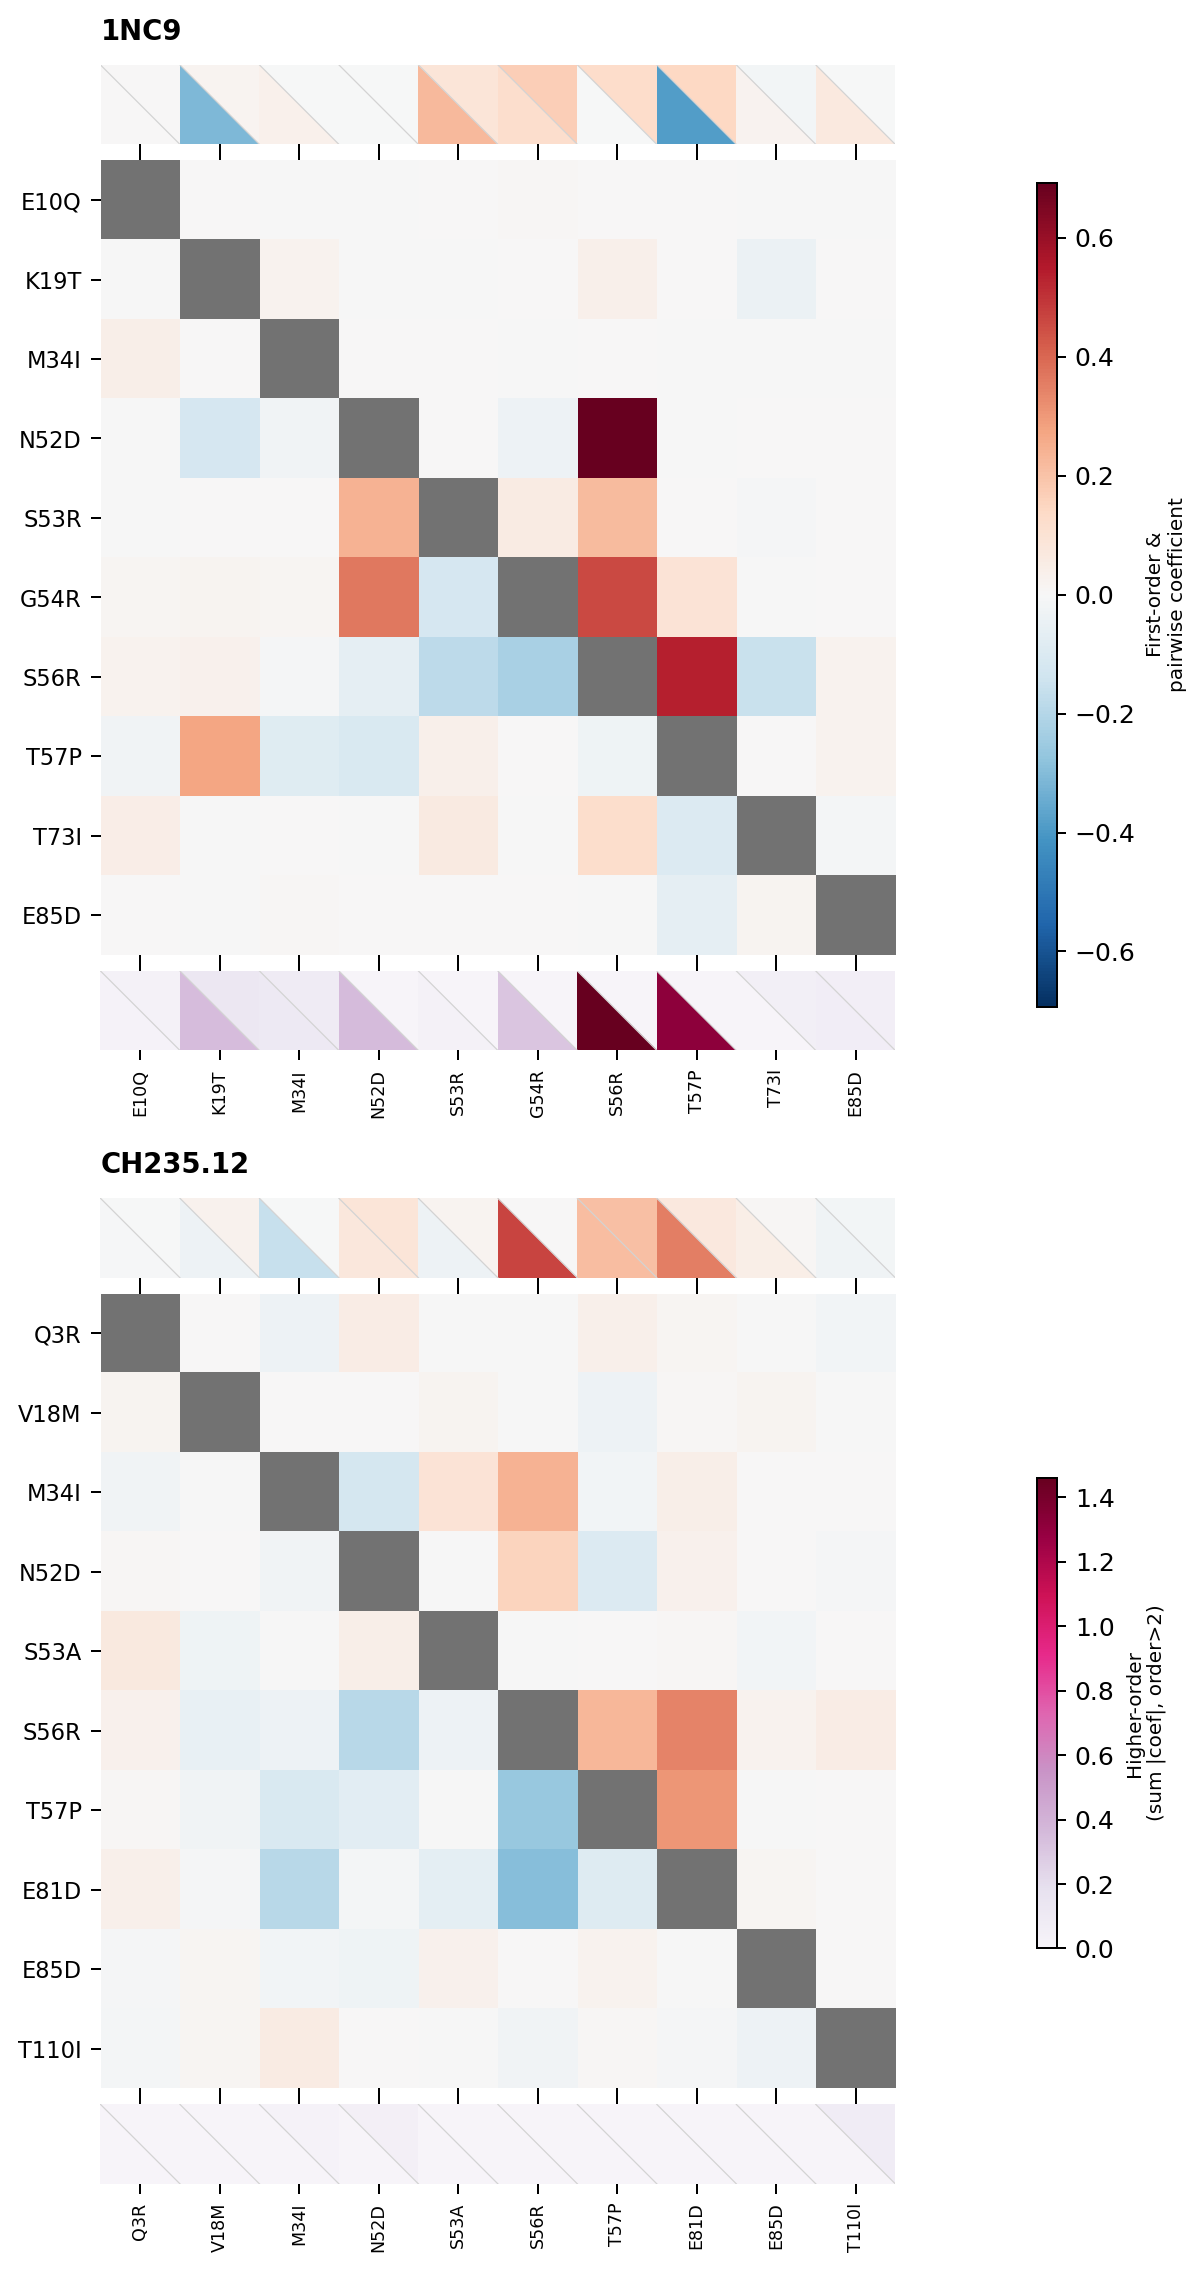

PosixPath('/root/Desktop/figures/final_fig/all_antibodies_global_split_order_heatmap.png')

In [ ]:
def plot_all_heatmaps_global_colormap(antibodies=None, antigens=None, out_name=None, show=False, clip_absmax=None):
    _antibodies = ANTIBODIES if antibodies is None else antibodies
    _antigens = ANTIGENS if antigens is None else antigens

    ag_a, ag_b = _antigens
    PAIR_BAD_COLOR = "0.45"  # This fixed grey is for the pairwise diagonal (n/a)

    all_order1_coeffs = []
    all_pair_coeffs = []
    all_higher_coeffs = []

    all_antibody_plotting_data = {}
    max_n = 0

    # collect all data and determine global color limits
    # iterate through all antibodies, but only process those with data for both antigens
    # ***current fix bc of some final tobits running will change after
    for antibody in _antibodies:
        if not all(find_final_params_file(antibody, ag) is not None for ag in _antigens):
            continue

        meta = get_site_annotation_table(antibody)
        n = len(meta)
        labels = meta.sort_values("site_index")["kabat_mutation"].tolist()

        if n == 0:
            # print(f"No sites found for {antibody}, skipping global heatmap for this antibody.") # Commented out
            continue

        order1_a, pair_a, higher_a = _load_order_arrays(antibody, ag_a, n)
        order1_b, pair_b, higher_b = _load_order_arrays(antibody, ag_b, n)

        all_order1_coeffs.extend(order1_a[~np.isnan(order1_a)].tolist())
        all_order1_coeffs.extend(order1_b[~np.isnan(order1_b)].tolist())
        all_pair_coeffs.extend(pair_a.ravel()[~np.isnan(pair_a.ravel())].tolist())
        all_pair_coeffs.extend(pair_b.ravel()[~np.isnan(pair_b.ravel())].tolist())
        all_higher_coeffs.extend(higher_a[~np.isnan(higher_a)].tolist())
        all_higher_coeffs.extend(higher_b[~np.isnan(higher_b)].tolist())

        all_antibody_plotting_data[antibody] = {
            "n": n, "labels": labels,
            "order1_a": order1_a, "pair_a": pair_a, "higher_a": higher_a,
            "order1_b": order1_b, "pair_b": pair_b, "higher_b": higher_b,
        }
        max_n = max(max_n, n)

    if not all_antibody_plotting_data:
        print("No antibody data available to plot a global heatmap.")
        return

    # calculate global norms from all collected coefficients
    _pair_absmax_value = None
    _pair_colorbar_extend = 'neither'

    if clip_absmax is not None:
        _pair_absmax_value = max(clip_absmax, 1e-6)
        _pair_colorbar_extend = 'both'
    else:
        # Auto-calculate if no explicit max is provided
        _calculated_pair_absmax = np.nanmax(np.abs(np.array(all_order1_coeffs + all_pair_coeffs))) if (all_order1_coeffs or all_pair_coeffs) else 1e-6
        _pair_absmax_value = max(_calculated_pair_absmax, 1e-6)
        _pair_colorbar_extend = 'neither'

    pair_absmax_global = _pair_absmax_value
    pair_norm_global = mcolors.TwoSlopeNorm(vmin=-pair_absmax_global, vcenter=0, vmax=pair_absmax_global)
    pair_cmap_global = plt.get_cmap("RdBu_r").copy()
    pair_cmap_global.set_bad(alpha=0)

    # calculate the specific global color for 0.0 from the global pairwise colormap
    pair_zero_color_global = pair_cmap_global(pair_norm_global(0.0))

    higher_max_global = np.nanmax(np.array(all_higher_coeffs)) if all_higher_coeffs else 1e-6
    higher_max_global = max(higher_max_global, 1e-6)
    # set vmin to 0 so that 0.0 values fall into the normal range of the colormap
    higher_norm_global = mcolors.Normalize(vmin=0, vmax=higher_max_global)
    higher_cmap_global = plt.get_cmap("PuRd").copy()
    higher_cmap_global.set_bad(alpha=0)

    # setup for global figure
    num_antibodies_to_plot = len(all_antibody_plotting_data)

    cell_size = 0.42 # approx size for one cell in the heatmap
    # Estimate figure width: base + max_n * cell_size + some margin for title/cbar
    fig_width = 2.7 + max_n * cell_size + 0.5
    # Estimate figure height: (2 * cell_size for order1/higher + max_n * cell_size for pairwise + padding) * num_antibodies
    fig_height = num_antibodies_to_plot * (2 * cell_size + max_n * cell_size) + num_antibodies_to_plot * 0.5 + 2 # Add buffer for titles/spacing

    fig = plt.figure(figsize=(fig_width, fig_height), dpi=180)

    # Use a main GridSpec to stack antibody blocks vertically
    main_gs = fig.add_gridspec(num_antibodies_to_plot, 1, hspace=0.15, top=0.95, bottom=0.05, left=0.1, right=0.85)

    # plot each antibody's heatmap
    for i, (antibody, data) in enumerate(all_antibody_plotting_data.items()):
        n = data["n"]
        labels = data["labels"]
        order1_a, pair_a, higher_a = data["order1_a"], data["pair_a"], data["higher_a"]
        order1_b, pair_b, higher_b = data["order1_b"], data["pair_b"], data["higher_b"]

        # create nested GridSpec for current antibody's 3 subpanels
        gs_antibody = main_gs[i].subgridspec(3, 1, height_ratios=[1, n, 1], hspace=0.05)

        ax1 = fig.add_subplot(gs_antibody[0])
        ax2 = fig.add_subplot(gs_antibody[1])
        ax3 = fig.add_subplot(gs_antibody[2])

        # add antibody title above its block
        # use ax1.set_title which is local to the subplot area
        ax1.set_title(f"{antibody}", fontsize=11, fontweight='bold', loc='left', pad=10)

        # call the helper function with global norms and control label drawing
        _draw_antibody_heatmap_subpanels(
            ax1, ax2, ax3, n, labels,
            order1_a, pair_a, higher_a,
            order1_b, pair_b, higher_b,
            pair_cmap_global, pair_norm_global, higher_cmap_global, higher_norm_global,
            ag_a, ag_b,
            draw_ylabel=True, # Always draw order labels (order 1, pairwise) for each antibody block
            draw_xlabel=True, # Always draw site labels for all antibody blocks
            pair_zero_color=pair_zero_color_global # Pass the calculated global zero color
        )

        # if not the last antibody, ensure no x-tick labels are shown
        # if i < num_antibodies_to_plot - 1:
        #     ax3.tick_params(labelbottom=False)
        #     ax3.set_xticklabels([])


    # fig.suptitle("Global Heatmap: First-order, Pairwise, and Higher-order Mutational Effects",
    #              fontsize=14, fontweight="bold", y=0.99) # Adjust y to prevent overlap with first antibody title
    # fig.text(0.5, 0.97,
    #           f"pairwise grid: upper triangle = {ag_a}, lower triangle = {ag_b}   |   "
    #           f"order 1 / order>2 squares: upper-right = {ag_a}, lower-left = {ag_b}",
    #           transform=fig.transFigure, ha="center", va="center", fontsize=9, color="#333333")

    fig.canvas.draw()

    # global colorbars
    # position colorbars on the right side, shared for all subplots
    cax1 = fig.add_axes([0.88, 0.55, 0.015, 0.35]) # [left, bottom, width, height] for pair_coef
    cb1 = fig.colorbar(plt.cm.ScalarMappable(norm=pair_norm_global, cmap=pair_cmap_global), cax=cax1, extend=_pair_colorbar_extend)
    cb1.set_label("First-order &\npairwise coefficient", fontsize=8)

    cax2 = fig.add_axes([0.88, 0.15, 0.015, 0.2]) # for higher_order_coef
    cb2 = fig.colorbar(plt.cm.ScalarMappable(norm=higher_norm_global, cmap=higher_cmap_global), cax=cax2)
    cb2.set_label("Higher-order\n(sum |coef|, order>2)", fontsize=8)

    # save figure
    out_name = out_name or f"all_antibodies_global_split_order_heatmap.png"
    save_figure(plt.gcf(), Path(out_name).stem)
    if show:
        plt.show()
    else:
        plt.close(fig)
    return None

plot_all_heatmaps_global_colormap(show=True)

Saved: /root/Desktop/figures/final_fig/1NC9_split_by_antigen_order_heatmap.png


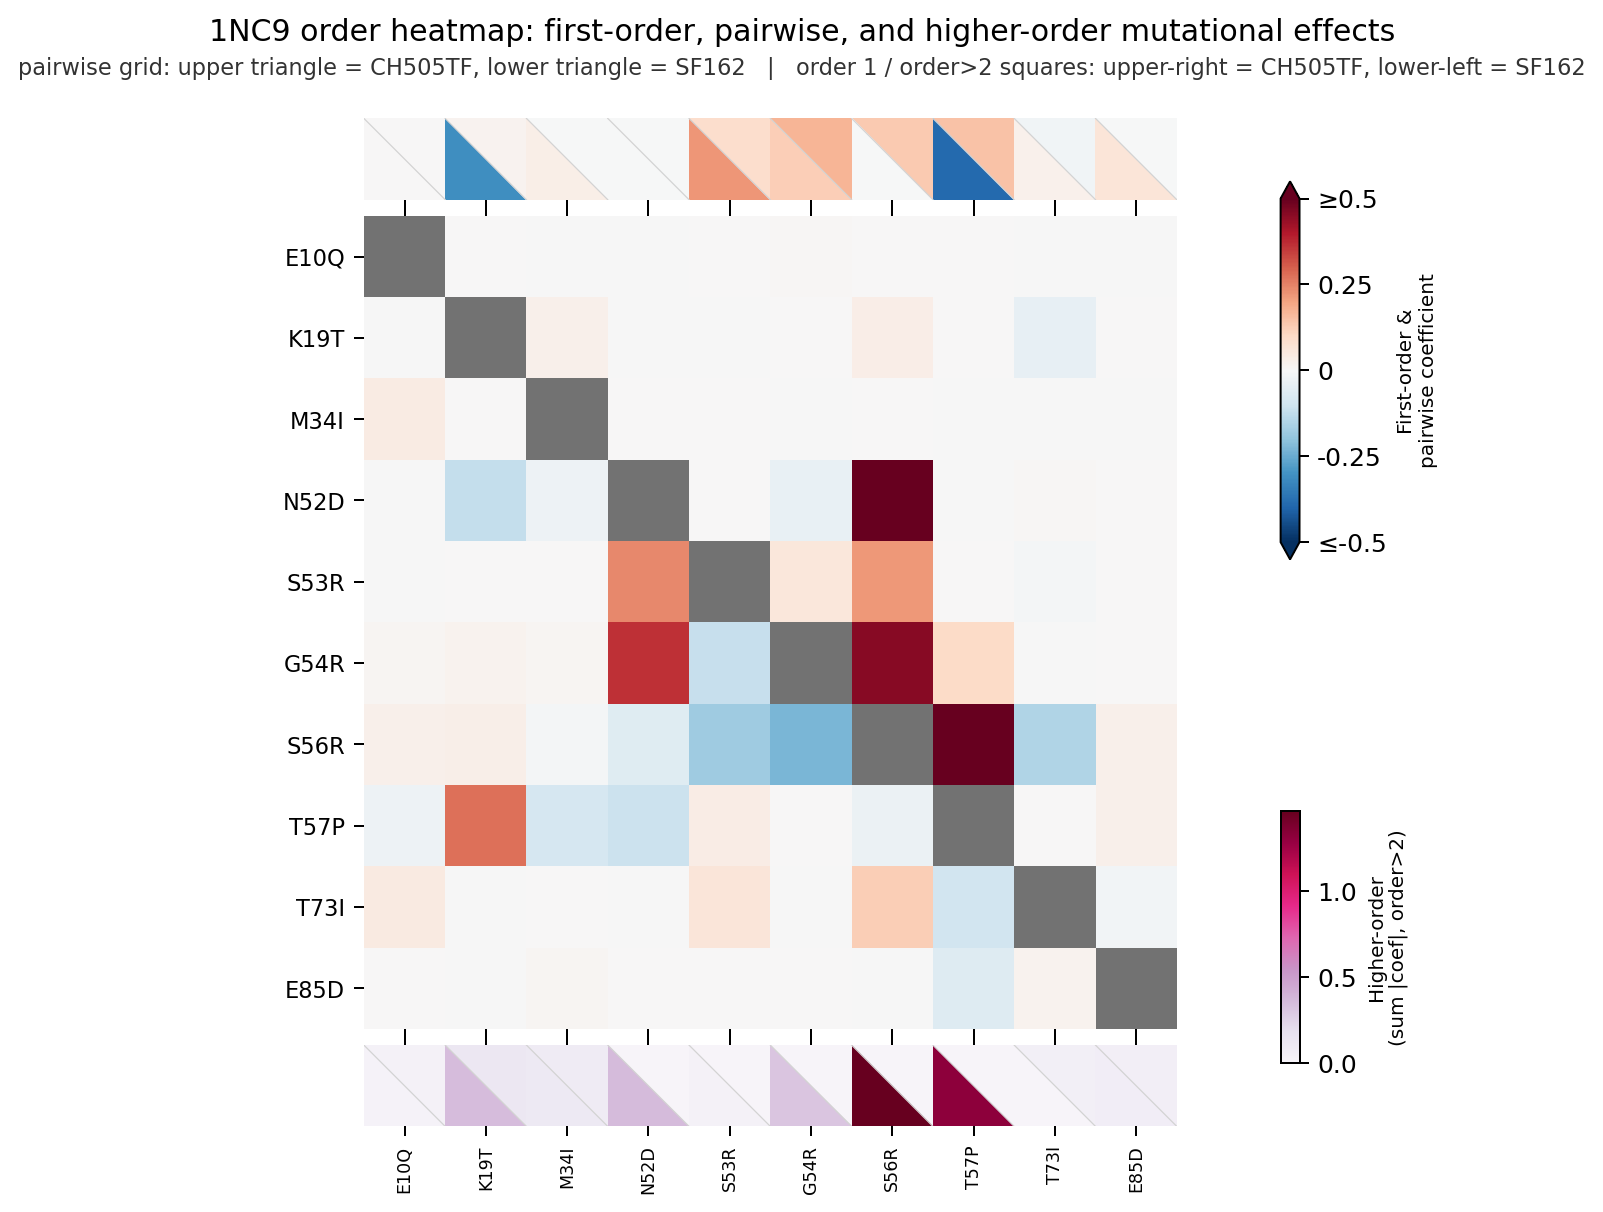

PosixPath('/root/Desktop/figures/final_fig/1NC9_split_by_antigen_order_heatmap.png')

In [ ]:
#clipped colormap version
plot_order_heatmap_split(
    antibody="1NC9",
    clip_absmax=0.5,
    show=True
)